# Chest X-Ray Pneumonia — Exploratory Data Analysis

This notebook walks through the dataset structure, visualises sample images,
analyses the class imbalance, and inspects pixel statistics before training.

**Prerequisites:** Download the dataset and ensure `data/chest_xray/` exists.

In [1]:
import sys
sys.path.insert(0, '../src')

import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

sns.set_theme(style='whitegrid', palette='muted')
DATA_DIR = Path('../data/chest_xray')
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
SPLITS = ['train', 'val', 'test']

## 1. Class Distribution

In [2]:
def count_images(data_dir: Path) -> pd.DataFrame:
    rows = []
    for split in SPLITS:
        for cls in CLASS_NAMES:
            cls_dir = data_dir / split / cls
            count = len(list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.jpg')) + list(cls_dir.glob('*.png'))) if cls_dir.exists() else 0
            rows.append({'split': split, 'class': cls, 'count': count})
    return pd.DataFrame(rows)

df_counts = count_images(DATA_DIR)
print(df_counts.pivot(index='split', columns='class', values='count'))

class  NORMAL  PNEUMONIA
split                   
test      234        390
train    1341       3875
val         8          8


C:\Users\benja\AppData\Local\Temp\ipykernel_28824\3575397678.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


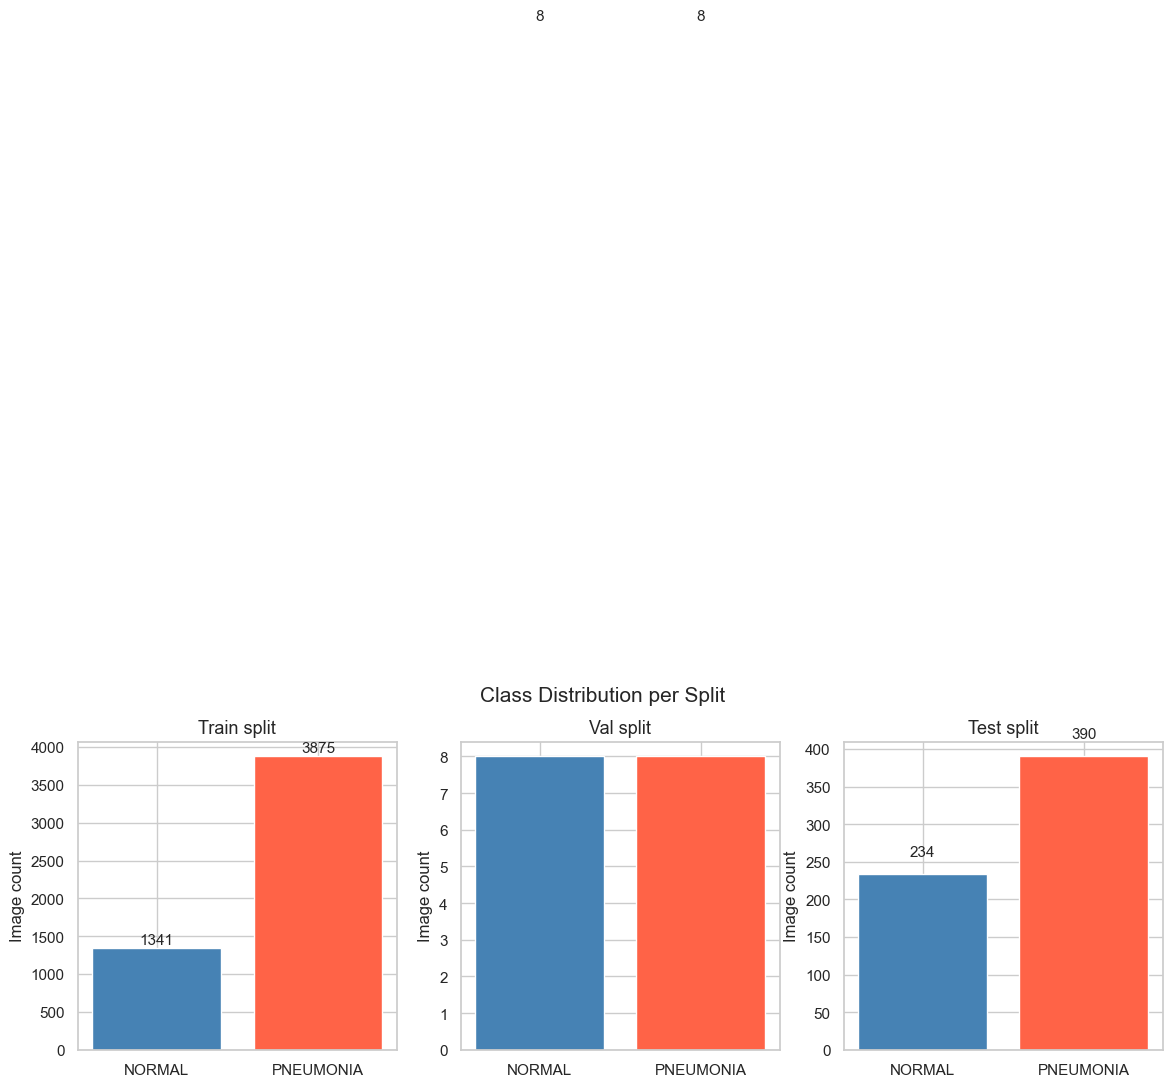

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, split in zip(axes, SPLITS):
    data = df_counts[df_counts['split'] == split]
    bars = ax.bar(data['class'], data['count'], color=['steelblue', 'tomato'])
    ax.set_title(f'{split.capitalize()} split', fontsize=13)
    ax.set_ylabel('Image count')
    for bar, val in zip(bars, data['count']):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20, str(val),
                ha='center', va='bottom', fontsize=11)
fig.suptitle('Class Distribution per Split', fontsize=15, y=1.02)
fig.tight_layout()
plt.show()

## 2. Sample Images

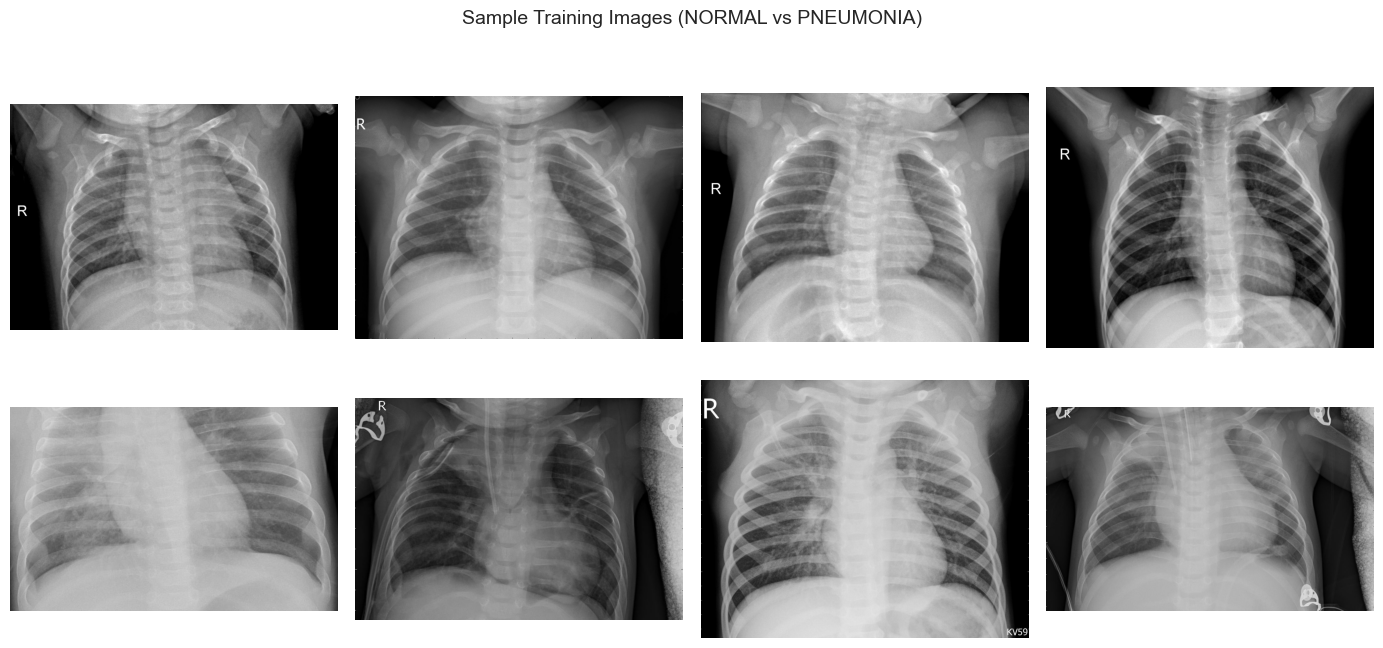

In [4]:
def get_sample_paths(data_dir: Path, split: str = 'train', n: int = 4) -> dict:
    samples = {}
    for cls in CLASS_NAMES:
        cls_dir = data_dir / split / cls
        all_files = list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.jpg'))
        samples[cls] = random.sample(all_files, min(n, len(all_files)))
    return samples

samples = get_sample_paths(DATA_DIR, split='train', n=4)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row_idx, cls in enumerate(CLASS_NAMES):
    for col_idx, img_path in enumerate(samples[cls]):
        img = Image.open(img_path).convert('RGB')
        axes[row_idx, col_idx].imshow(img, cmap='gray')
        axes[row_idx, col_idx].axis('off')
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(cls, fontsize=13, rotation=90, labelpad=10)
fig.suptitle('Sample Training Images (NORMAL vs PNEUMONIA)', fontsize=14)
fig.tight_layout()
plt.show()

## 3. Image Size Distribution

In [5]:
def collect_image_sizes(data_dir: Path, split: str = 'train', max_per_class: int = 200) -> pd.DataFrame:
    rows = []
    for cls in CLASS_NAMES:
        cls_dir = data_dir / split / cls
        paths = list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.jpg'))
        for p in paths[:max_per_class]:
            with Image.open(p) as img:
                w, h = img.size
            rows.append({'class': cls, 'width': w, 'height': h})
    return pd.DataFrame(rows)

df_sizes = collect_image_sizes(DATA_DIR, split='train', max_per_class=300)
print(df_sizes.groupby('class')[['width', 'height']].describe().round(1))

           width                                                       height  \
           count    mean    std    min     25%     50%     75%     max  count   
class                                                                           
NORMAL     300.0  1669.9  267.5  994.0  1483.0  1654.0  1816.0  2538.0  300.0   
PNEUMONIA  300.0  1237.0  272.9  502.0  1048.0  1176.0  1392.0  2093.0  300.0   

                                                                 
             mean    std    min     25%     50%     75%     max  
class                                                            
NORMAL     1350.9  289.7  747.0  1148.0  1316.0  1508.0  2411.0  
PNEUMONIA   849.6  266.5  307.0   678.0   792.0   960.0  1944.0  


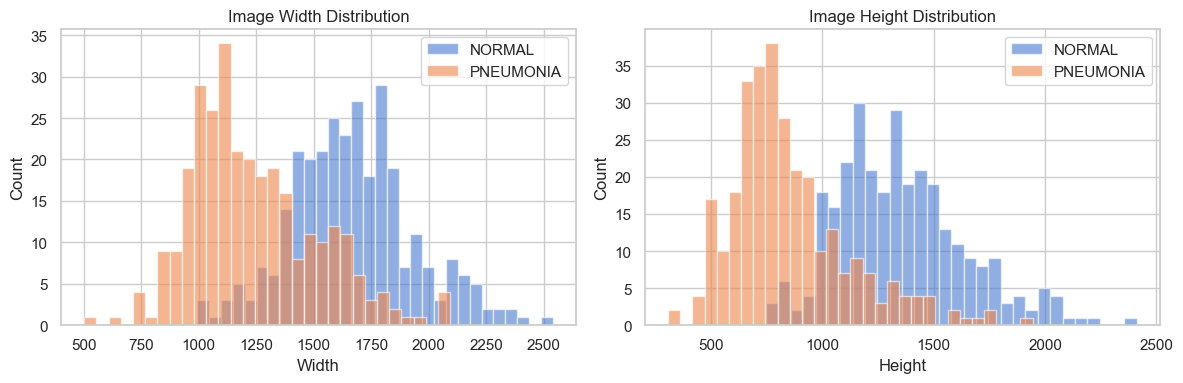

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, dim in zip(axes, ['width', 'height']):
    for cls in CLASS_NAMES:
        subset = df_sizes[df_sizes['class'] == cls][dim]
        ax.hist(subset, bins=30, alpha=0.6, label=cls)
    ax.set_xlabel(dim.capitalize())
    ax.set_ylabel('Count')
    ax.set_title(f'Image {dim.capitalize()} Distribution')
    ax.legend()
fig.tight_layout()
plt.show()

## 4. Pixel Intensity Statistics

In [7]:
import torchvision.transforms as T

def compute_channel_stats(data_dir: Path, split: str = 'train', max_per_class: int = 100):
    """Estimate per-channel mean and std over a random subset of images."""
    transform = T.Compose([T.Resize((224, 224)), T.ToTensor()])
    pixels = []
    for cls in CLASS_NAMES:
        cls_dir = data_dir / split / cls
        paths = list(cls_dir.glob('*.jpeg')) + list(cls_dir.glob('*.jpg'))
        for p in random.sample(paths, min(max_per_class, len(paths))):
            img = Image.open(p).convert('RGB')
            tensor = transform(img)  # (3, H, W)
            pixels.append(tensor.numpy())
    all_pixels = np.stack(pixels)  # (N, 3, H, W)
    mean = all_pixels.mean(axis=(0, 2, 3))
    std  = all_pixels.std(axis=(0, 2, 3))
    return mean, std

mean, std = compute_channel_stats(DATA_DIR)
print('Estimated dataset statistics (R, G, B channels):')
print(f'  Mean : {mean}')
print(f'  Std  : {std}')
print()
print('ImageNet statistics used for normalisation:')
print('  Mean : [0.485, 0.456, 0.406]')
print('  Std  : [0.229, 0.224, 0.225]')

Estimated dataset statistics (R, G, B channels):
  Mean : [0.48764366 0.48764366 0.48764366]
  Std  : [0.24136011 0.24136011 0.24136011]

ImageNet statistics used for normalisation:
  Mean : [0.485, 0.456, 0.406]
  Std  : [0.229, 0.224, 0.225]


## 5. Class Imbalance — Weighted Sampler Simulation

In [8]:
train_counts = df_counts[df_counts['split'] == 'train'].set_index('class')['count']
total = train_counts.sum()
imbalance_ratio = train_counts['PNEUMONIA'] / train_counts['NORMAL']

print('Training set class counts:')
for cls, cnt in train_counts.items():
    print(f'  {cls}: {cnt}  ({100*cnt/total:.1f}%)')
print(f'\nImbalance ratio (PNEUMONIA / NORMAL): {imbalance_ratio:.2f}x')
print()
print('WeightedRandomSampler equalises this by assigning each NORMAL image')
print(f'{imbalance_ratio:.1f}x more weight than each PNEUMONIA image.')

Training set class counts:
  NORMAL: 1341  (25.7%)
  PNEUMONIA: 3875  (74.3%)

Imbalance ratio (PNEUMONIA / NORMAL): 2.89x

WeightedRandomSampler equalises this by assigning each NORMAL image
2.9x more weight than each PNEUMONIA image.


## 6. Data Augmentation Preview

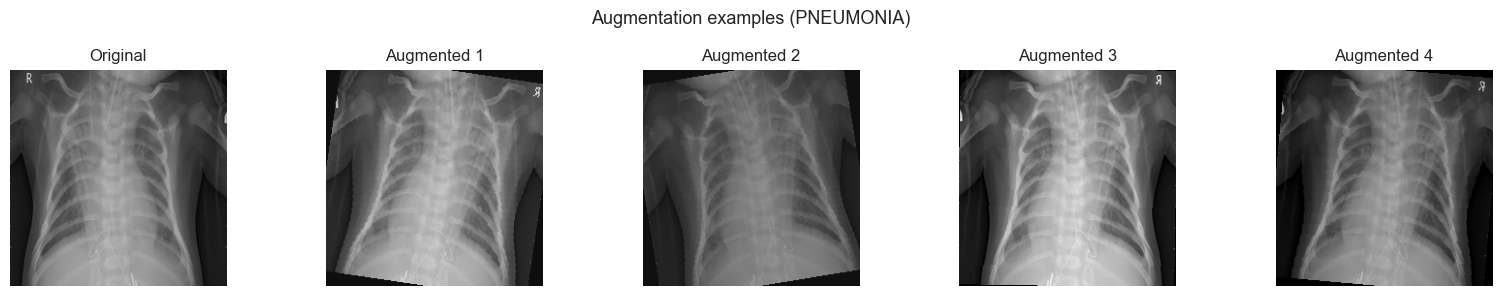

In [9]:
import torchvision.transforms as T

augmentation = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=1.0),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
])

# Pick one PNEUMONIA image
sample_path = random.choice(
    list((DATA_DIR / 'train' / 'PNEUMONIA').glob('*.jpeg'))
)
original = Image.open(sample_path).convert('RGB').resize((224, 224))

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
axes[0].imshow(original)
axes[0].set_title('Original')
axes[0].axis('off')
for i in range(1, 5):
    aug = augmentation(original)
    axes[i].imshow(aug)
    axes[i].set_title(f'Augmented {i}')
    axes[i].axis('off')
fig.suptitle('Augmentation examples (PNEUMONIA)', fontsize=13)
fig.tight_layout()
plt.show()

## Summary

| Observation | Detail |
|---|---|
| Training set size | See counts above |
| Class imbalance | PNEUMONIA >> NORMAL (~3:1) |
| Image sizes | Variable; resized to 224×224 for the model |
| Normalisation | ImageNet statistics (close to dataset statistics) |
| Augmentation | Horizontal flip, ±10° rotation, colour jitter |

Proceed to training:
```bash
python src/train.py --config config/config.yaml
```